# RiseTogether Preprocessing Script

This notebook contains the preprocessing and analysis code for thesis by Aurelija Spunde.

The preprocessing pipeline is mainly based on Stropahl et al. (2018). The code is based on tutorials from MNE-Python documentation page (https://mne.tools/stable/auto_tutorials/intro/10_overview.html#preprocessing and other tutorials) and some parts are based on Luke Ring's code from github repository (https://github.com/NexusDynamic/RiseTogether-analysis/tree/main).

**Pipeline:**
1. Loading the packages and raws
2. Applying montage and dropping mastoid channels from EEG recordings
3. Fitting ICA on a filtered copy of raw data
4. Running CORRMAP and excluding eye movement artifacts
5. Applying ICA weights to the unfiltered raw data
6. Filtering the data for analysis
7. Identifying bad channels and interpolating them
8. Epoching the data
9. Computing the evoked responses
10. Computing the grand average across subjects

### 1. Loading the packages and the data

In [ ]:
import mne
import sys
import os
import numpy as np
import pandas as pd
from pathlib import Path
import polars as pl
# %matplotlib widget
# inline  
import matplotlib.pyplot as plt
import pyprep
from pyprep.find_noisy_channels import NoisyChannels
from preprocessing_pipeline import run_ica, make_epochs, select_events, from_session_time


In [2]:
ica_output_folder = Path("/work/analysis/preprocessing/data/ica_results") # ica weights
clean_data_folder = Path("/work/analysis/preprocessing/data/clean_eeg_data") # data cleaned of eye artifacts
processed_data_folder = Path("/work/analysis/preprocessing/data/processed_eeg_data") # fully preprocessed data ready for analysis

os.makedirs(ica_output_folder, exist_ok=True)
os.makedirs(processed_data_folder, exist_ok=True)
os.makedirs(clean_data_folder, exist_ok=True)

In [3]:
# Loading BIDS data

from rt_bids import read_session, read_recording, session_events, session_phases, crop_session, by_team, read_motion, to_session_time, from_session_time

BIDS_ROOT = "/work/RiseTogetherEEG/VideoGameParadigm-EEG"

In [4]:
# Loading in the BIDS sessions (code taken from Luke Ring's notebook at https://github.com/NexusDynamic/RiseTogether-analysis/blob/main/explore/s03_ica_explorer.ipynb)

SESSIONS = sorted(pd.read_csv(Path(BIDS_ROOT) / "participants.tsv", sep="\t")["group"].unique())
raws, events, phases = {}, {}, {}
for session in SESSIONS:
    raws[session] = read_session(BIDS_ROOT, session)          # {participant_id: Raw}
    phases[session] = session_phases(BIDS_ROOT, session)      # index: phase name; start/end in session time (s)
    ev = session_events(BIDS_ROOT, session)                   # every beh event; onset in session time (s)
    ev["session"] = session
    events[session] = ev
    print(f"{session}: EEG for {len(raws[session])} participants: {', '.join(raws[session])}")


Setting channel info structure...
Setting channel info structure...
Setting channel info structure...
Setting channel info structure...
Creating raw.info structure...
Setting channel info structure...
Creating raw.info structure...
Creating raw.info structure...
Creating raw.info structure...
session01: EEG for 6 participants: sub-001, sub-002, sub-003, sub-004, sub-005, sub-006
session02: EEG for 6 participants: sub-007, sub-008, sub-009, sub-010, sub-011, sub-012
session03: EEG for 6 participants: sub-013, sub-014, sub-015, sub-016, sub-017, sub-018
session04: EEG for 6 participants: sub-019, sub-020, sub-021, sub-022, sub-023, sub-024
session05: EEG for 6 participants: sub-025, sub-026, sub-027, sub-028, sub-029, sub-030
session06: EEG for 6 participants: sub-031, sub-032, sub-033, sub-034, sub-035, sub-036
session07: EEG for 5 participants: sub-038, sub-039, sub-040, sub-041, sub-042
session08: EEG for 4 participants: sub-043, sub-044, sub-046, sub-048


### 2. and 3. Applying montage, dropping mastoids and fitting ICA on a filtered copy of the raws

In [5]:
# Define montage

montage = mne.channels.make_standard_montage("colin27_1020")

Participant sub-007...


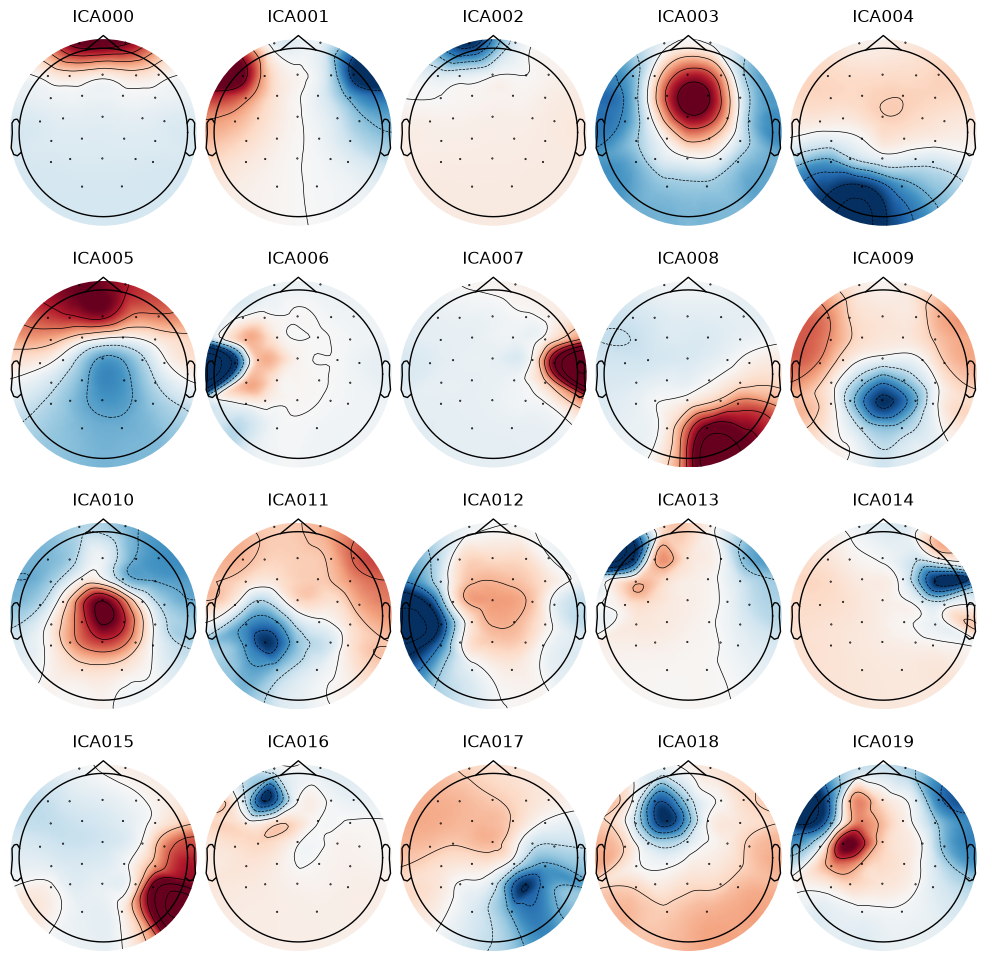

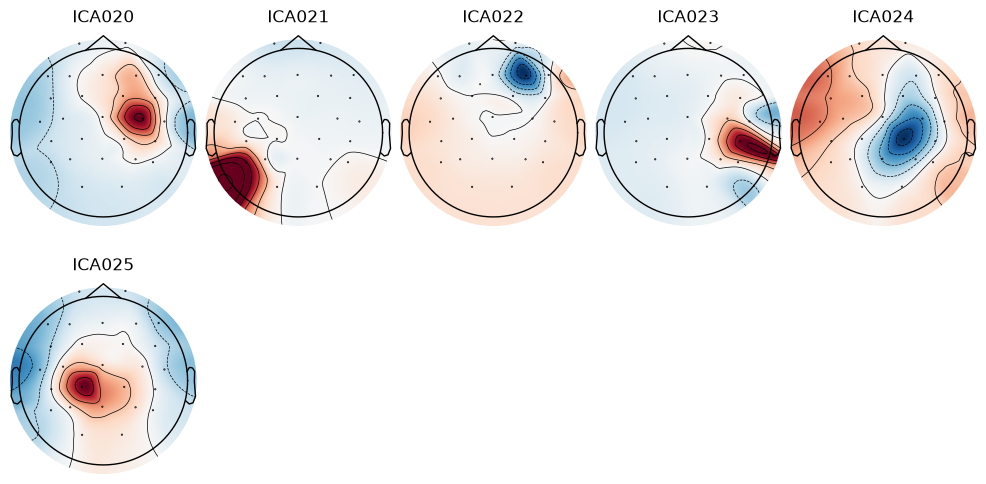

Participant sub-008...


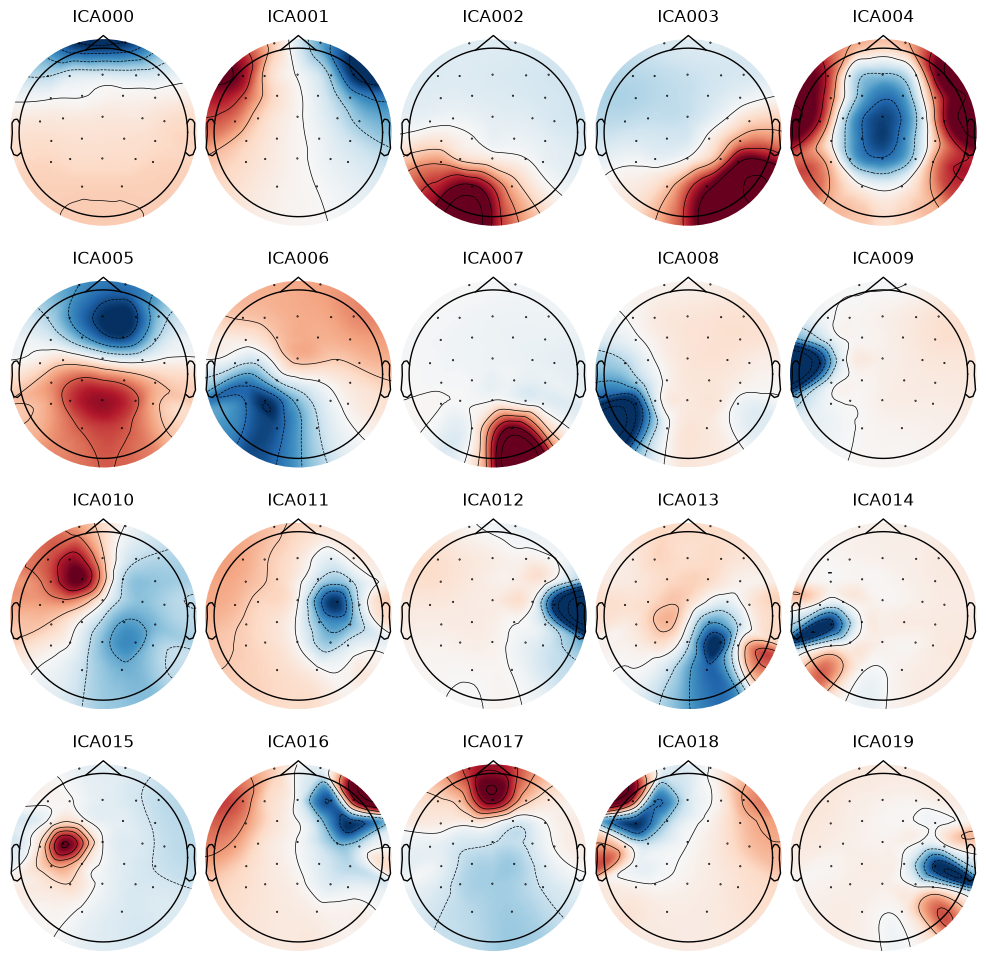

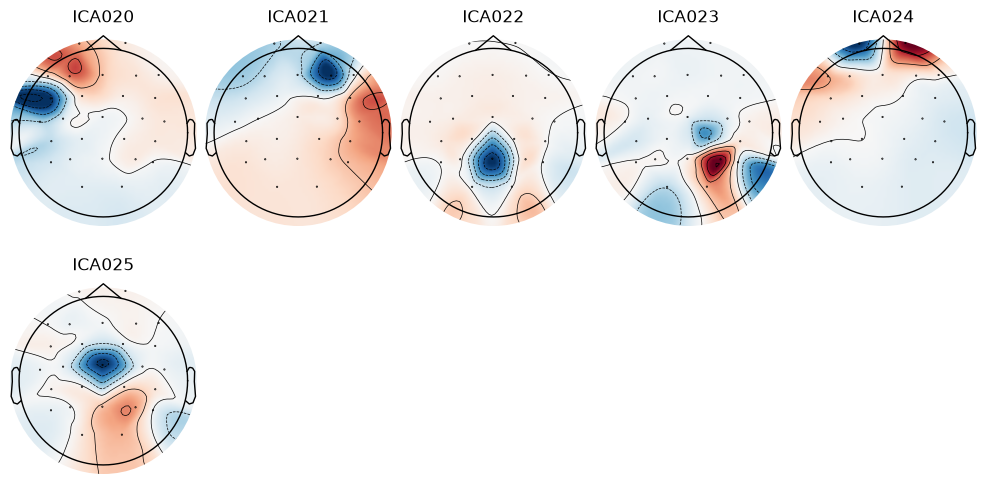

Participant sub-009...


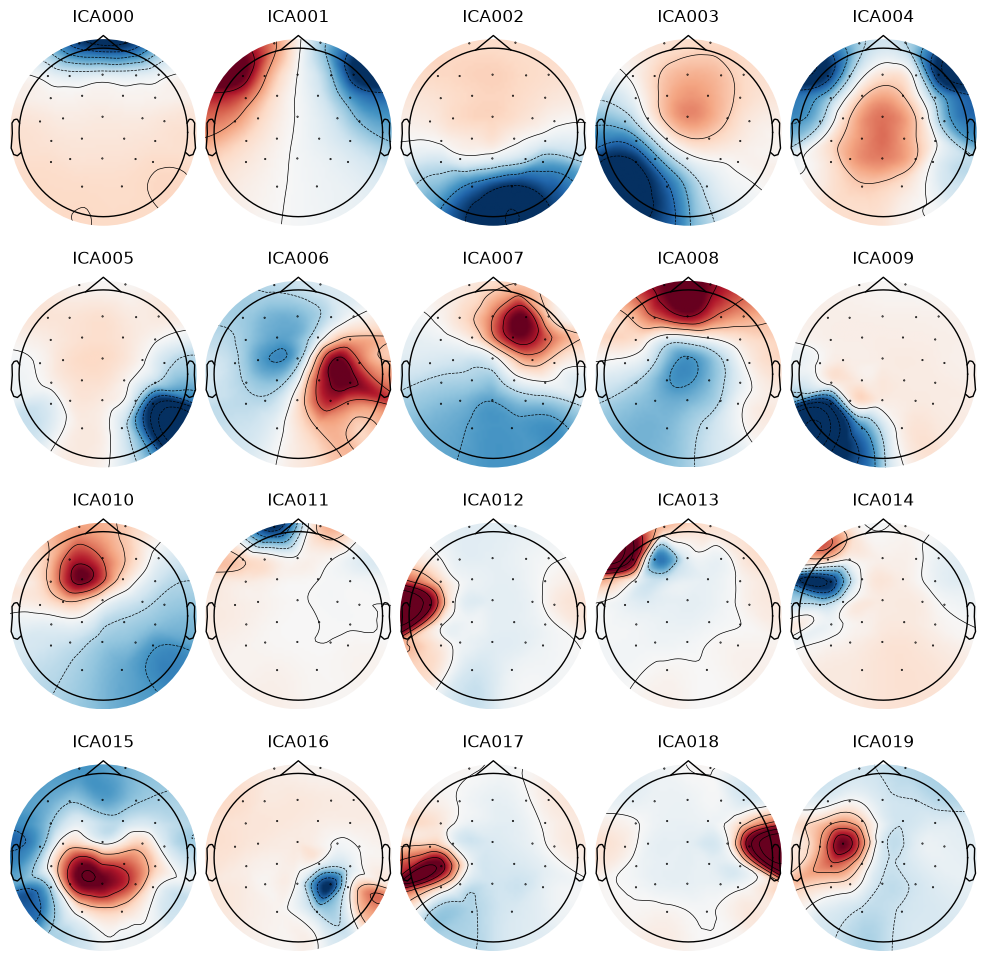

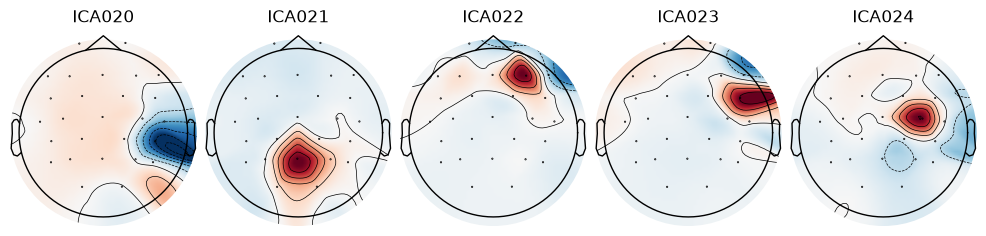

Participant sub-010...


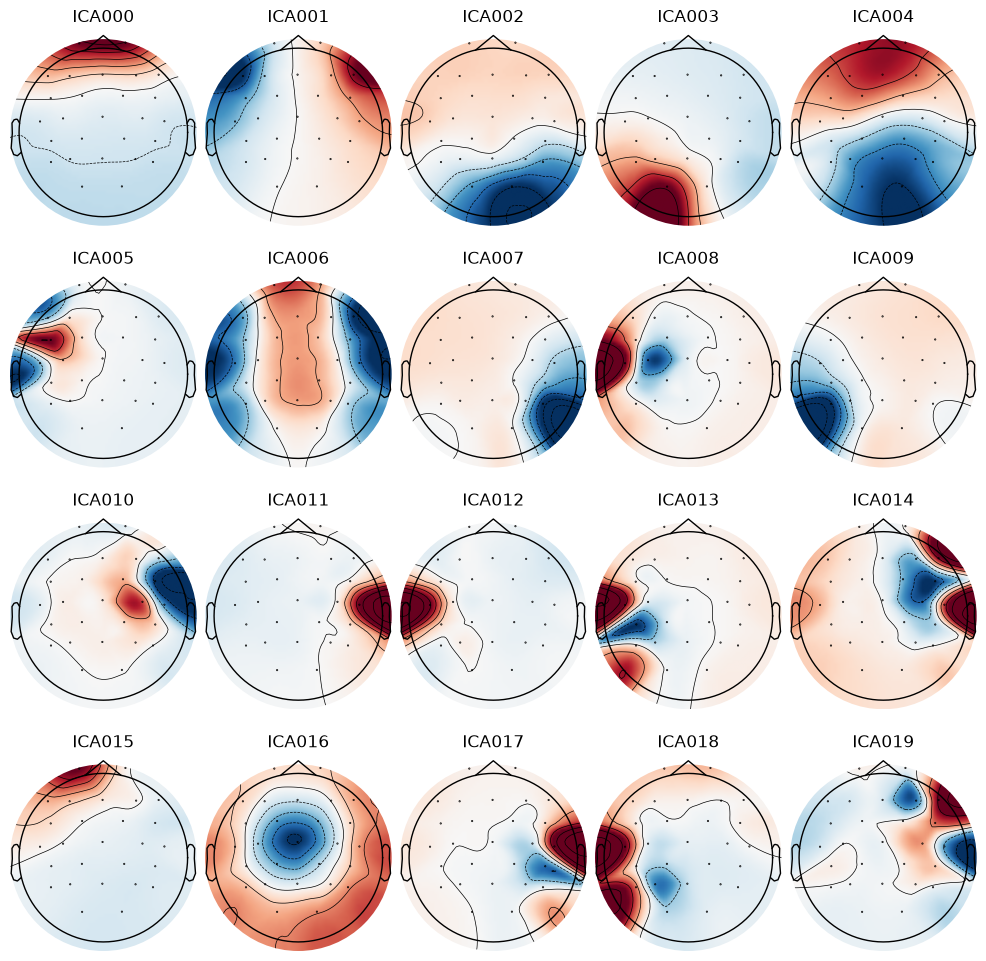

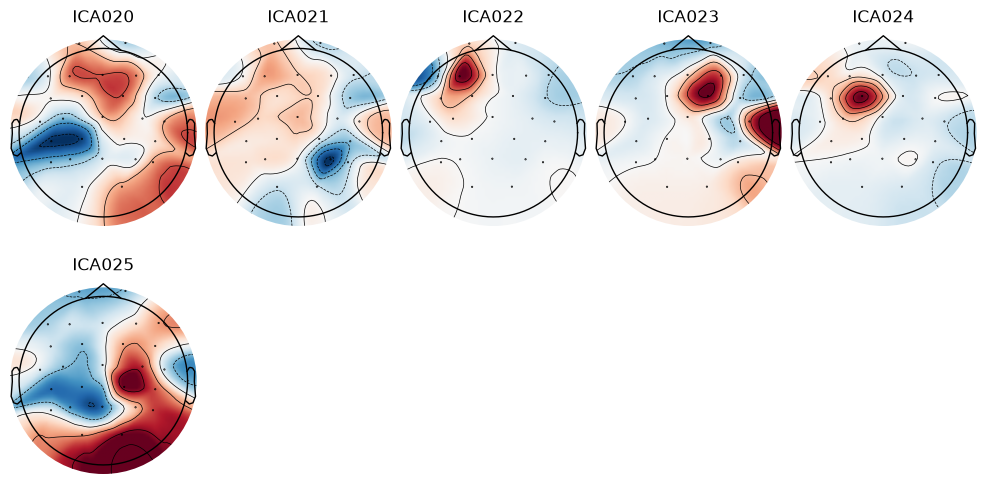

Participant sub-011...


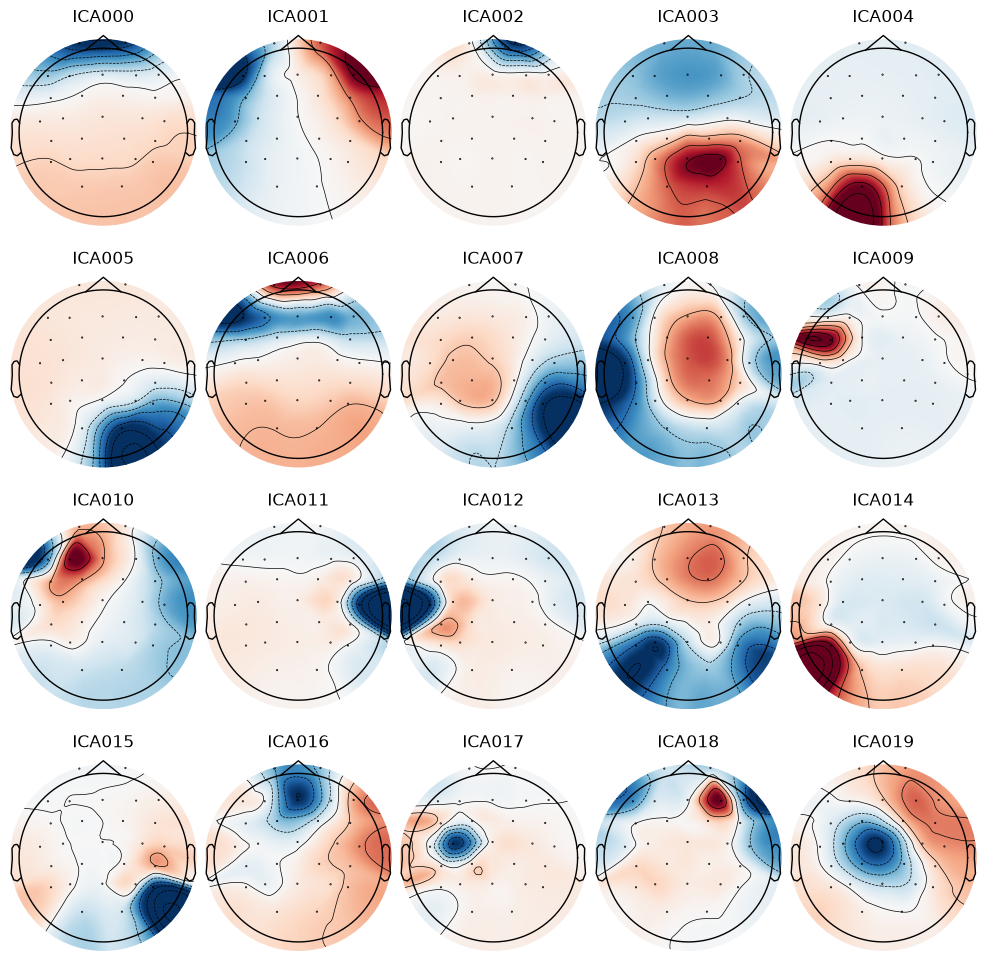

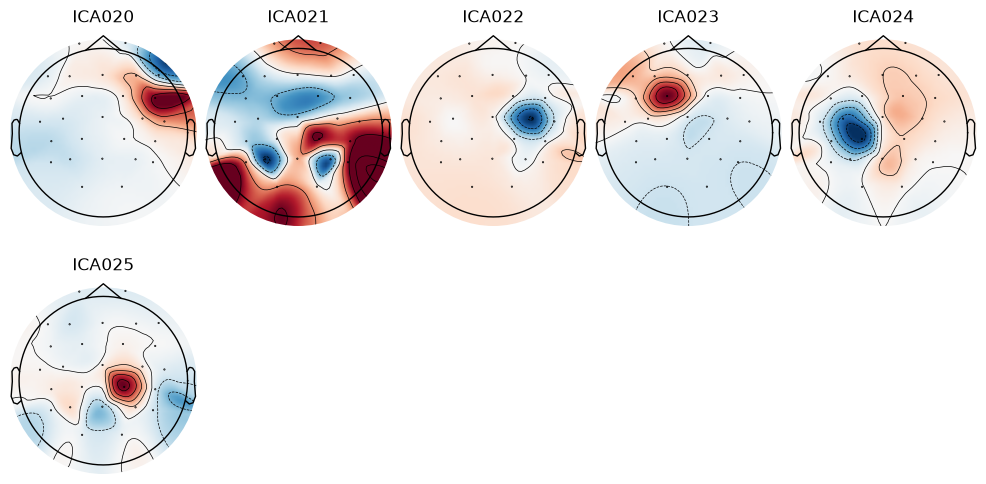

Participant sub-012...


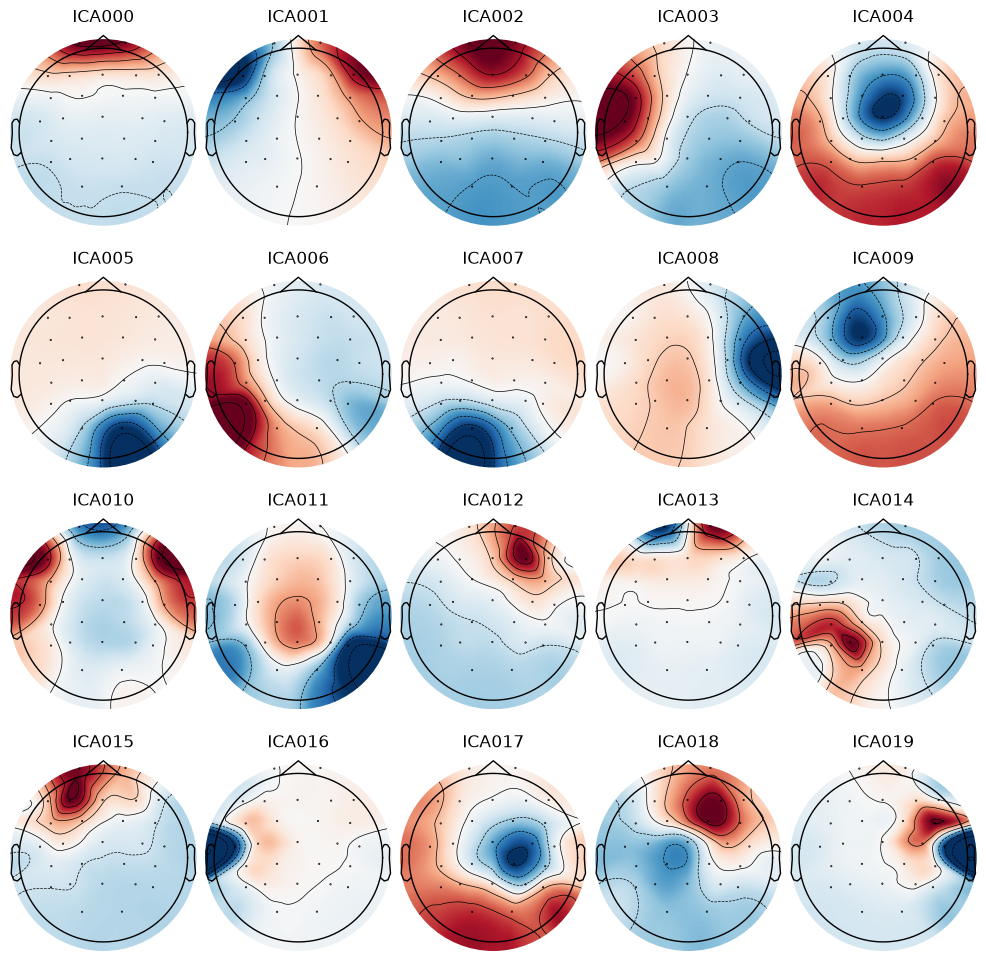

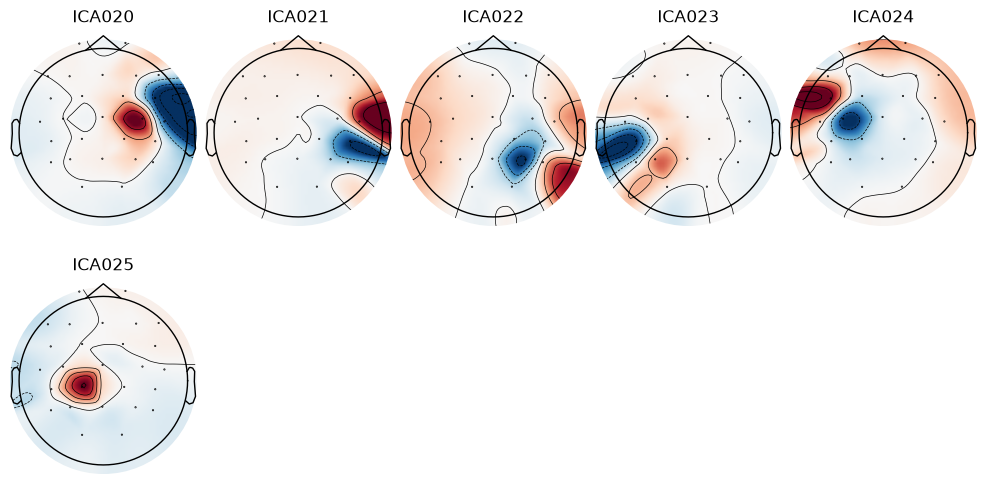

In [6]:
# For all sessions

'''
icas = []

for session in SESSIONS:
        for sub in raws[session]:

            print(f"Participant {sub}...")
            raw = raws[session][sub]

'''


# Just one session check

icas = []

for sub in raws["session02"]:

    print(f"Participant {sub}...")
    raw = raws["session02"][sub]

    # Apply montage and drop mastoids

    raw.set_montage(montage)
    raw.load_data()
    raw.pick("eeg")
    to_drop = [ch for ch in ["M1", "M2"] if ch in raw.ch_names]
    if to_drop:
        raw.drop_channels(to_drop)

    # ICA fitted on the 1s lond dummy epochs (see preprocessing_pipeline.py)

    ica = run_ica(raw = raw, sub = sub, ica_output_folder = ica_output_folder, h_freq = 40, l_freq = 1)
    icas.append(ica)


### 4. CORRMAP

In [7]:
# Selecting template indices from a participant's ICs
template_subject = 1 # subject 008 in this case

template_indices = [0, 1] # I chose ICs 001 and 002 from sub-008

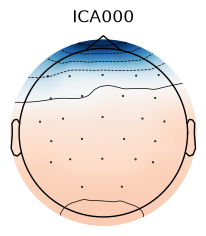

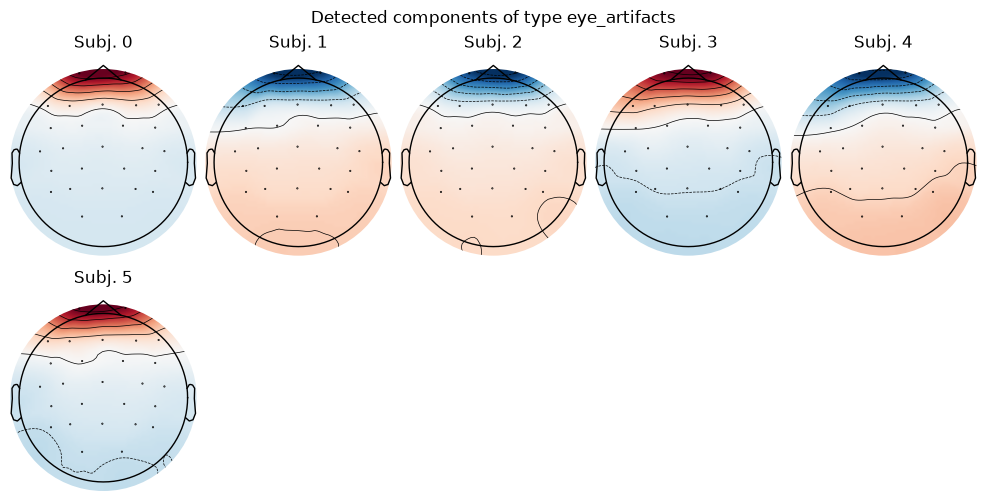

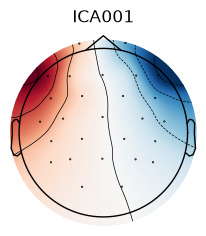

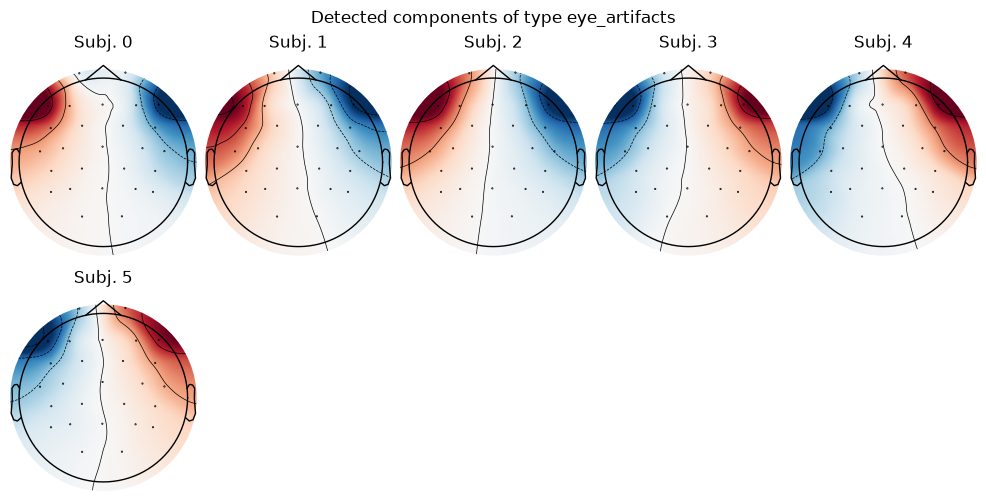

In [12]:
for ic_idx in template_indices:
  
  mne.preprocessing.corrmap(
        icas, 
        template=(template_subject, ic_idx),
        threshold="auto",
        label="eye_artifacts",
        plot=True,
        show=True,
    )

### 

In [13]:
for ica in icas:
    eye_artifacts = ica.labels_.get("eye_artifacts", [])
    ica.exclude = sorted(set(ica.exclude) | set(eye_artifacts))

In [19]:
# Applying the updated exclusions

for ica, sub in zip(icas, raws["session02"]):
    raw = raws["session02"][sub]
    raw_clean = raw.copy()
    ica.apply(raw_clean)
    raw_clean.save(os.path.join(clean_data_folder, f"{sub}_clean_raw.fif"), overwrite=True)

### 6. Filtering the data for analysis

In [20]:
raws_clean = []

'''
when running for all sessions and participants change to:

for session in SESSIONS:
        for sub in raws[session]:

            print(f"Participant {sub}...")
'''

for sub in raws["session02"]: # update for all sessions and participants
    raw_cleaned = mne.io.read_raw_fif(clean_data_folder / f'{sub}_clean_raw.fif')
    raws_clean.append(raw_cleaned)

In [28]:
raws_filtered = []

for raw in raws_clean:
    
    raw_filt = raw.copy().load_data().filter(l_freq=0.1, h_freq=40)

    sub = Path(raw.filenames[0]).stem.split("_")[0]

    raws_filtered.append(raw_filt)

    print(f"Bad channels for participant {sub}: ", raw_filt.info["bads"])

Bad channels for participant sub-007_clean_raw:  []
Bad channels for participant sub-008_clean_raw:  []
Bad channels for participant sub-009_clean_raw:  ['O1']
Bad channels for participant sub-010_clean_raw:  []
Bad channels for participant sub-011_clean_raw:  []
Bad channels for participant sub-012_clean_raw:  []


### 7. Identifying bad channels and interpolating them

In [ ]:
# Detecting noisy channels using pyprep which implements 
# all of the noisy channel detection methods used in the PREP pipeline, 
# as described in Bigdely-Shamlo, N., Mullen, T., Kothe, C., Su, K. M., Robbins, K. A. (2015). The PREP pipeline: standardized preprocessing for large-scale EEG analysis. Frontiers in Neuroinformatics, 9, 16. 

for raw in raws_filtered:

    nd = NoisyChannels(raw, do_detrend=True, random_state=1337)

    nd.find_bad_by_deviation(deviation_threshold=5.0)

    sub = Path(raw.filenames[0]).stem.split("_")[0]

    print(f"Detected bad channels for participant {sub}:", nd.get_bads(as_dict=True))


Detected bad channels by deviation: {'bad_by_nan': [], 'bad_by_flat': [], 'bad_by_deviation': [], 'bad_by_hf_noise': [], 'bad_by_correlation': [], 'bad_by_SNR': [], 'bad_by_dropout': [], 'bad_by_psd': [], 'bad_by_ransac': [], 'bad_by_manual': [], 'bad_all': []}
Detected bad channels by deviation: {'bad_by_nan': [], 'bad_by_flat': [], 'bad_by_deviation': [], 'bad_by_hf_noise': [], 'bad_by_correlation': [], 'bad_by_SNR': [], 'bad_by_dropout': [], 'bad_by_psd': [], 'bad_by_ransac': [], 'bad_by_manual': [], 'bad_all': []}
Detected bad channels by deviation: {'bad_by_nan': [], 'bad_by_flat': [], 'bad_by_deviation': [], 'bad_by_hf_noise': [], 'bad_by_correlation': [], 'bad_by_SNR': [], 'bad_by_dropout': [], 'bad_by_psd': [], 'bad_by_ransac': [], 'bad_by_manual': ['O1'], 'bad_all': ['O1']}
Detected bad channels by deviation: {'bad_by_nan': [], 'bad_by_flat': [], 'bad_by_deviation': [], 'bad_by_hf_noise': [], 'bad_by_correlation': [], 'bad_by_SNR': [], 'bad_by_dropout': [], 'bad_by_psd': [], '

In [ ]:
# Creating a dictionary of bad channels per all participants for later reporting

bad_channels_per_participant = {
    "sub-001": [],
    "sub-002": [],
    "sub-003": [],
    "sub-004": [],
    "sub-005": [],
    "sub-006": [],
    "sub-007": [],
    "sub-008": [],
    "sub-009": ["O1"],
    "sub-010": [],
    "sub-011": [],
    "sub-012": [],
    "sub-013": [],
    "sub-014": [],
    "sub-015": [],
    "sub-016": [],
    "sub-017": [],
    "sub-018": []
}

In [33]:
# Interpolating bad channels, rereferencing to the common average and saving the raws in the preprocessed files 

for raw in raws_filtered:

    if raw.info["bads"]:

        raw.interpolate_bads()

    raw.pick(['eeg'], exclude='bads')

    raw.set_eeg_reference("average")

    sub = Path(raw.filenames[0]).stem.split("_")[0]

    raw.save(os.path.join(processed_data_folder, f"{sub}_preprocessed_raw.fif"), overwrite=True)

### 8. Epoching data

In [5]:
# Loading in the preprocessed files

raws_preprocessed = []

for sub in raws["session02"]: # update for all sessions and participants
    raw_preprocessed = mne.io.read_raw_fif(processed_data_folder / f'{sub}_preprocessed_raw.fif')
    raws_preprocessed.append(raw_preprocessed)

In [6]:
# Getting the events
# Code from Luke Ring (https://github.com/NexusDynamic/RiseTogether-analysis/blob/main/explore/s03_ica_explorer.ipynb)

ALL_EVENTS = pd.concat(events.values(), ignore_index=True)
# Columns used for selecting and grouping (missing values get a name so they can be chosen too):
ALL_EVENTS["value"] = ALL_EVENTS["value"].fillna("-")
ALL_EVENTS["condition"] = ALL_EVENTS["condition"].fillna("-")
# Screen half of a touch (x is the fraction of the screen's width, 0 = left edge)
ALL_EVENTS["side"] = np.select([ALL_EVENTS["x"] < 0.5, ALL_EVENTS["x"] >= 0.5], ["left", "right"], "-")
# Teams only exist in joint play, and team numbers restart in every session, so a team is "session + number"
ALL_EVENTS["team"] = np.where(ALL_EVENTS["team_id"].isna(), "no team",
                              ALL_EVENTS["session"] + " team " + ALL_EVENTS["team_id"].astype(str))
events = {session: ev for session, ev in ALL_EVENTS.groupby("session")}

In [7]:
print("\nEvent types (trial_type / value), number of events in all sessions, per condition:")
catalogue = ALL_EVENTS.pivot_table(index=["trial_type", "value"], columns="condition", values="onset",
                                   aggfunc="size", fill_value=0)
catalogue


Event types (trial_type / value), number of events in all sessions, per condition:


,condition,-,individual,joint,motor_baseline
trial_type,value,,,,
BALL_FATAL_WALL,-,0,1744,6456,0
BALL_LEVEL_END,-,0,504,7614,0
CONTROL_REVERSAL_END,zone_exit,0,2276,20118,0
CONTROL_REVERSAL_START,zone,0,2286,20244,0
CONTROL_REVERSAL_ZONE_ENTER,-,0,2286,20244,0
CONTROL_REVERSAL_ZONE_EXIT,-,0,2276,20118,0
COUNTDOWN_CANCEL,-,2350,0,56,0
COUNTDOWN_COMPLETE,-,0,2409,8553,0
COUNTDOWN_START,-,1563,2300,7242,0


Selecting events for epoching

In [ ]:
# Selecting events for epoching

GROUP_COLUMNS = {"none": None, "session": "session", "participant": "participant_id", "team": "team",
                 "condition": "condition", "side": "side", "value": "value"}

ev = select_events(
    session="session02",
    trial_type="BALL_FATAL_WALL", # a trial_type of beh/*_events.tsv
    values= [], # its values to use
    conditions=["individual", "joint"], # condition column ("-" = no condition)
    side="any", # "any", "left" or "right": screen half of a touch
    group_by="condition", # a key of GROUP_COLUMNS
)

In [ ]:
epochs_by_sub = {}
for sub, raw in raws_preprocessed["session02"].items():
    epochs, n_gaps = make_epochs(
        raw,
        ev,
        tmin=-0.2,
        tmax=0.8,
        baseline= None # no baseline correction for now otherways (-0.2, 0.0)
        # do i add rejection criteria here?
    )
    if epochs is not None:
        epochs_by_sub[sub] = epochs
        print(f"{sub}: {len(epochs)} epochs ({n_gaps} skipped due to sample gaps)")

### 9. Computing Evoked Responses

In [ ]:
# Overall evoked per subject
evokeds_by_sub = {sub: epochs.average() for sub, epochs in epochs_by_sub.items()}

# Or per group in epochs.metadata (e.g., condition / group)
groups = next(iter(epochs_by_sub.values())).metadata["group"].unique()
evokeds_by_group = {grp: {} for grp in groups}

for sub, epochs in epochs_by_sub.items():
    for grp in groups:
        sub_epochs = epochs[f"group == '{grp}'"]
        if len(sub_epochs) > 0:
            evokeds_by_group[grp][sub] = sub_epochs.average()

In [ ]:
# Plotting the evoked responses for the first subject

first_sub = next(iter(evokeds_by_sub))
evokeds_by_sub[first_sub].plot(spatial_colors=True)
evokeds_by_sub[first_sub].plot_topomap(times=[0.1, 0.2, 0.3, 0.4])

### 10. Computing the Grand Average Across Subjects

In [ ]:
grand_avg = mne.grand_average(list(evokeds_by_sub.values()))
grand_avg.plot(spatial_colors=True)
grand_avg.plot_joint()  # combines butterfly/channel traces + topomaps at peaks

# Comparing conditions/groups on one grand-average plot:
grand_by_group = {
    grp: mne.grand_average(list(sub_dict.values()))
    for grp, sub_dict in evokeds_by_group.items()
    if len(sub_dict) > 0
}
mne.viz.plot_compare_evokeds(grand_by_group, combine="mean")